# Consigna 2.1 Variantes de una CNN vista en clase
**Matias Agustin Elizaincin · Sistemas Inteligentes · Universidad CAECE**

Se elige **Caece - Redes neuronales convolucionales - Números - Modo Uso de RNC**, provisto por la cátedra.
La base conserva Conv2D(32), MaxPool, Conv2D(64), MaxPool, Flatten y Dense(100).
Se comparan capacidad, regularización y duración; cada variante tiene su justificación junto al código.

**Ejecución conservada:** completada en Google Colab el 20 de noviembre de 2026 con GPU disponible; las salidas y los resultados corresponden a esa ejecución.
Abrir en Colab, elegir **Entorno de ejecución → Cambiar tipo de entorno → GPU T4** y ejecutar todas las celdas en orden.
La disponibilidad de GPU depende de Colab; la lista de dispositivos registra lo usado realmente.
Las 5 épocas de referencia vienen del Colab del profesor. La salida usa logits en vez de softmax
para calcular una pérdida numéricamente estable; softmax se aplica al interpretar predicciones.


In [1]:
import os, json, time, platform, sys, shutil, hashlib
from pathlib import Path
from datetime import datetime, timezone
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
from IPython.display import display

SEMILLA = 2026
tf.keras.utils.set_random_seed(SEMILLA)
tf.config.experimental.enable_op_determinism()
if 'google.colab' in sys.modules:
    BASE = Path('/content/Actividad_Integradora')
elif '__file__' in globals():
    BASE = Path(__file__).resolve().parents[1] / '02_Resultados'
else:
    actual = Path.cwd().resolve()
    candidatos = [actual/'Actividades'/'Actividad Integradora', actual/'Actividad Integradora', actual.parent, actual]
    raiz = next((p for p in candidatos if (p/'01_Cuadernos').is_dir()), actual)
    BASE = raiz / '02_Resultados'
BASE.mkdir(parents=True, exist_ok=True)
print('TensorFlow:', tf.__version__, 'NumPy:', np.__version__)
print('GPU disponibles:', tf.config.list_physical_devices('GPU'))
print('Directorio de resultados:', BASE.resolve())


TensorFlow: 2.21.0 NumPy: 2.4.6
GPU disponibles: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Directorio de resultados: /content/Actividad_Integradora


## Datos y separación de validación
MNIST tiene 60.000 imágenes de entrenamiento y 10.000 de prueba. Se reservan 600 por dígito
del entrenamiento para validación: quedan 54.000 para ajustar pesos y 6.000 para comparar variantes.
Las 10.000 de prueba permanecen aparte hasta terminar la selección. Normalizar divide los píxeles por 255.


In [2]:
(imagenes, etiquetas), (test_images, test_labels) = datasets.mnist.load_data()
imagenes = imagenes.astype('float32')[...,None] / 255.0
test_images = test_images.astype('float32')[...,None] / 255.0
assert imagenes.shape == (60000,28,28,1) and test_images.shape == (10000,28,28,1)
assert 0 <= imagenes.min() <= imagenes.max() <= 1
CARPETA = BASE/'MNIST'; CARPETA.mkdir(exist_ok=True)


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [3]:
def particion_estratificada(y, cantidad_por_clase, seed=SEMILLA):
    # La validación sale exclusivamente del entrenamiento oficial.
    rng = np.random.default_rng(seed)
    entrenamiento, validacion = [], []
    for clase in range(10):
        indices = np.flatnonzero(y.reshape(-1) == clase)
        rng.shuffle(indices)
        validacion.extend(indices[:cantidad_por_clase])
        entrenamiento.extend(indices[cantidad_por_clase:])
    entrenamiento, validacion = np.array(entrenamiento), np.array(validacion)
    rng.shuffle(entrenamiento)
    rng.shuffle(validacion)
    assert len(np.intersect1d(entrenamiento, validacion)) == 0
    assert len(entrenamiento)+len(validacion) == len(y)
    return entrenamiento, validacion

def lotes(x, y, batch_size=128, entrenamiento=False):
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if entrenamiento:
        ds = ds.shuffle(len(x), seed=SEMILLA, reshuffle_each_iteration=True)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

def graficar_historial(historia, nombre, carpeta):
    epocas = np.arange(1, len(historia['loss'])+1)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    for clave, titulo, eje in [('accuracy','Exactitud',ax[0]), ('loss','Pérdida',ax[1])]:
        eje.plot(epocas, historia[clave], label='Entrenamiento')
        eje.plot(epocas, historia['val_'+clave], label='Validación')
        eje.set(xlabel='Época', ylabel=titulo, title=titulo)
        eje.grid(alpha=.25); eje.legend()
    ax[0].set_ylim(0, 1)
    fig.suptitle(nombre); fig.tight_layout()
    fig.savefig(carpeta/f'{nombre}_curvas.png', dpi=180)
    plt.show()

def guardar_entorno(carpeta):
    info = {'fecha_utc': datetime.now(timezone.utc).isoformat(), 'python':sys.version,
            'plataforma':platform.platform(), 'semilla':SEMILLA,
            'dispositivos':[str(d) for d in tf.config.list_physical_devices()],
            'paquetes':{p:metadata.version(p) for p in ['tensorflow','keras','numpy','pandas','matplotlib']}}
    (carpeta/'entorno.json').write_text(json.dumps(info,indent=2,ensure_ascii=False),encoding='utf-8')

def firma_experimento(modelo, epocas, arrays):
    # El respaldo solo se reutiliza si coinciden datos, arquitectura y configuración.
    config = {'protocolo': 'CNN-2026-v2', 'semilla': SEMILLA, 'epocas': epocas,
              'batch_size': 128, 'adam_learning_rate': 0.001,
              'tensorflow': tf.__version__, 'keras': metadata.version('keras'),
              'arquitectura': json.loads(modelo.to_json()), 'datos': []}
    for a in arrays:
        a = np.ascontiguousarray(a)
        config['datos'].append({'forma': list(a.shape), 'dtype': str(a.dtype),
                               'sha256': hashlib.sha256(memoryview(a).cast('B')).hexdigest()})
    return hashlib.sha256(json.dumps(config,sort_keys=True).encode()).hexdigest()

def entrenar(nombre, constructor, epocas, x_train, y_train, x_val, y_val, carpeta):
    # Cada experimento empieza desde cero con el mismo split y la misma semilla.
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEMILLA)
    modelo = constructor()
    modelo.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
                   loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                   metrics=['accuracy'])
    firma = firma_experimento(modelo, epocas, (x_train,y_train,x_val,y_val))
    archivo = carpeta/f'{nombre}.keras'
    respaldo = carpeta/f'{nombre}_registro.json'
    historial = carpeta/f'{nombre}_historia.json'
    if respaldo.exists() and archivo.exists() and historial.exists():
        previo = json.loads(respaldo.read_text(encoding='utf-8'))
        if previo.get('firma') == firma:
            datos = json.loads(historial.read_text(encoding='utf-8'))
            assert all(len(datos[k]) == epocas for k in ['loss','accuracy','val_loss','val_accuracy'])
            assert all(np.isfinite(v).all() for v in datos.values())
            assert hashlib.sha256(archivo.read_bytes()).hexdigest() == previo['modelo_sha256']
            restaurado = tf.keras.models.load_model(archivo)
            assert restaurado.count_params() == modelo.count_params()
            print('Corrida completa recuperada sin repetir entrenamiento:', nombre)
            if not (carpeta/f'{nombre}_curvas.png').exists():
                graficar_historial(datos,nombre,carpeta)
            return previo['registro']
    print('\nExperimento:',nombre,'| Épocas:',epocas)
    modelo.summary()
    resumen=[]; modelo.summary(print_fn=lambda s:resumen.append(s))
    (carpeta/f'{nombre}_arquitectura.txt').write_text('\n'.join(resumen),encoding='utf-8')
    callbacks=[tf.keras.callbacks.CSVLogger(str(carpeta/f'{nombre}_epocas.csv')),
               tf.keras.callbacks.TerminateOnNaN()]
    inicio=time.perf_counter()
    historia=modelo.fit(lotes(x_train,y_train,entrenamiento=True),
                        validation_data=lotes(x_val,y_val), epochs=epocas,
                        callbacks=callbacks, verbose=2)
    duracion=time.perf_counter()-inicio
    assert len(historia.history['loss']) == epocas, 'El entrenamiento terminó antes de lo solicitado.'
    assert all(np.isfinite(v).all() for v in historia.history.values())
    modelo.save(archivo)
    registro={'experimento':nombre, 'epocas':epocas,'parametros':modelo.count_params(),
              'duracion_segundos':duracion, 'archivo_modelo':archivo.name,
              **{k:float(v[-1]) for k,v in historia.history.items()}}
    (carpeta/f'{nombre}_historia.json').write_text(json.dumps(historia.history,indent=2),encoding='utf-8')
    respaldo.write_text(json.dumps({'firma': firma, 'estado': 'corrida_completa',
        'modelo_sha256': hashlib.sha256(archivo.read_bytes()).hexdigest(),
        'registro': registro},indent=2,ensure_ascii=False),encoding='utf-8')
    graficar_historial(historia.history,nombre,carpeta)
    return registro

def evaluar(nombre, x_test, y_test, carpeta):
    modelo=tf.keras.models.load_model(carpeta/f'{nombre}.keras')
    perd,acc=modelo.evaluate(lotes(x_test,y_test),verbose=2)
    logits=modelo.predict(lotes(x_test,y_test),verbose=0)
    prob=tf.nn.softmax(logits,axis=1).numpy()
    pred=prob.argmax(axis=1)
    assert np.allclose(prob.sum(axis=1),1,atol=1e-6)
    assert np.isclose(np.mean(pred==y_test.reshape(-1)),acc,atol=1e-6)
    pd.DataFrame({'indice':np.arange(len(pred)),'clase_real':y_test.reshape(-1),
                  'clase_predicha':pred,'probabilidad_maxima':prob.max(axis=1)}).to_csv(carpeta/f'{nombre}_predicciones.csv',index=False)
    return {'experimento':nombre,'test_loss':float(perd),'test_accuracy':float(acc)}, prob

def exportar(carpeta):
    archivo=shutil.make_archive(str(carpeta), 'zip', root_dir=carpeta)
    print('Resultados guardados:',archivo)
    try:
        from google.colab import files
    except ImportError:
        return
    files.download(archivo)


Entrenamiento: 54000 Validación: 6000 Prueba: 10000


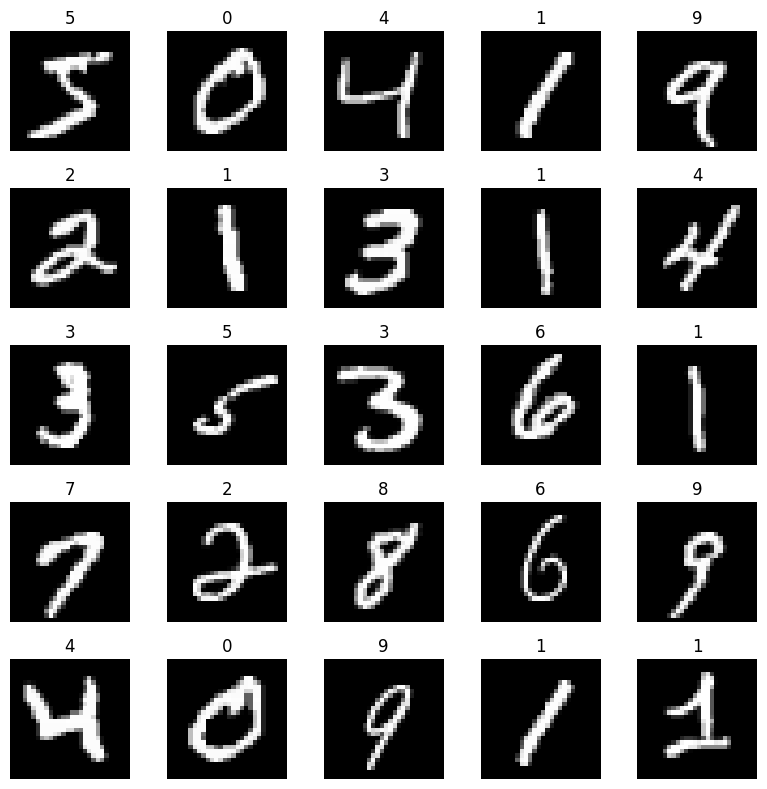

In [4]:
idx_train,idx_val=particion_estratificada(etiquetas,600)
x_train,y_train=imagenes[idx_train],etiquetas[idx_train]
x_val,y_val=imagenes[idx_val],etiquetas[idx_val]
np.savez_compressed(CARPETA/'indices_split.npz',train=idx_train,validacion=idx_val)
print('Entrenamiento:',len(x_train),'Validación:',len(x_val),'Prueba:',len(test_images))
guardar_entorno(CARPETA)
fig,axs=plt.subplots(5,5,figsize=(8,8))
for i,ax in enumerate(axs.flat):
    ax.imshow(imagenes[i,:,:,0],cmap='gray'); ax.set_title(str(etiquetas[i])); ax.axis('off')
fig.tight_layout(); fig.savefig(CARPETA/'primeras_25.png',dpi=180); plt.show()


## Modelo de referencia y variantes justificadas
- **M0 base, 5 épocas:** reproduce las dos convoluciones y la capa densa del Colab elegido.
- **M1 compacta, 5 épocas:** baja filtros de 32/64 a 16/32 y Dense de 100 a 64. Evalúa si se conserva exactitud con menos parámetros.
- **M2 dropout, 5 épocas:** mantiene la capacidad base y agrega Dropout(0,30) antes de la salida para estudiar la brecha entre entrenamiento y validación.
- **M3 base, 8 épocas:** conserva arquitectura y optimizador; cambia solo la duración para estudiar mejora, estabilización o sobreajuste.

Se conserva Adam(0,001), lotes de 128 y el mismo conjunto de validación. Cambiar varias cantidades
en M1 es una variante de capacidad global; no permite atribuir el efecto a una sola capa.



Experimento: M0_base_5 | Épocas: 5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100)            │       160,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 179,926 (702.84 KB)

 Trainable params: 179,926 (702.84 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
422/422 - 8s - 20ms/step - accuracy: 0.9336 - loss: 0.2237 - val_accuracy: 0.9775 - val_loss: 0.0772
Epoch 2/5
422/422 - 3s - 7ms/step - accuracy: 0.9817 - loss: 0.0610 - val_accuracy: 0.9808 - val_loss: 0.0632
Epoch 3/5
422/422 - 4s - 9ms/step - accuracy: 0.9867 - loss: 0.0432 - val_accuracy: 0.9852 - val_loss: 0.0502
Epoch 4/5
422/422 - 3s - 7ms/step - accuracy: 0.9896 - loss: 0.0327 - val_accuracy: 0.9872 - val_loss: 0.0452
Epoch 5/5
422/422 - 3s - 7ms/step - accuracy: 0.9917 - loss: 0.0258 - val_accuracy: 0.9840 - val_loss: 0.0525


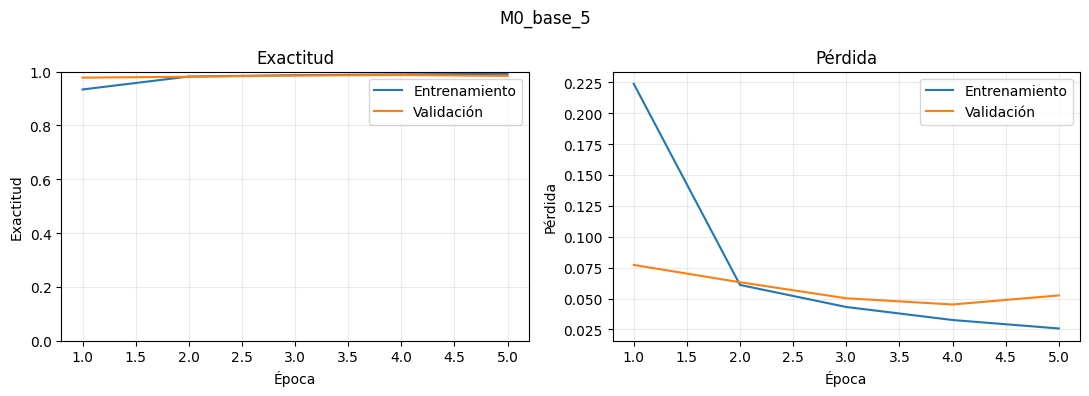


Experimento: M1_compacta_5 | Épocas: 5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,714 (221.54 KB)

 Trainable params: 56,714 (221.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
422/422 - 5s - 13ms/step - accuracy: 0.9011 - loss: 0.3330 - val_accuracy: 0.9672 - val_loss: 0.1091
Epoch 2/5
422/422 - 4s - 9ms/step - accuracy: 0.9748 - loss: 0.0831 - val_accuracy: 0.9765 - val_loss: 0.0754
Epoch 3/5
422/422 - 3s - 6ms/step - accuracy: 0.9817 - loss: 0.0592 - val_accuracy: 0.9803 - val_loss: 0.0638
Epoch 4/5
422/422 - 3s - 7ms/step - accuracy: 0.9848 - loss: 0.0479 - val_accuracy: 0.9822 - val_loss: 0.0563
Epoch 5/5
422/422 - 4s - 9ms/step - accuracy: 0.9879 - loss: 0.0391 - val_accuracy: 0.9812 - val_loss: 0.0652


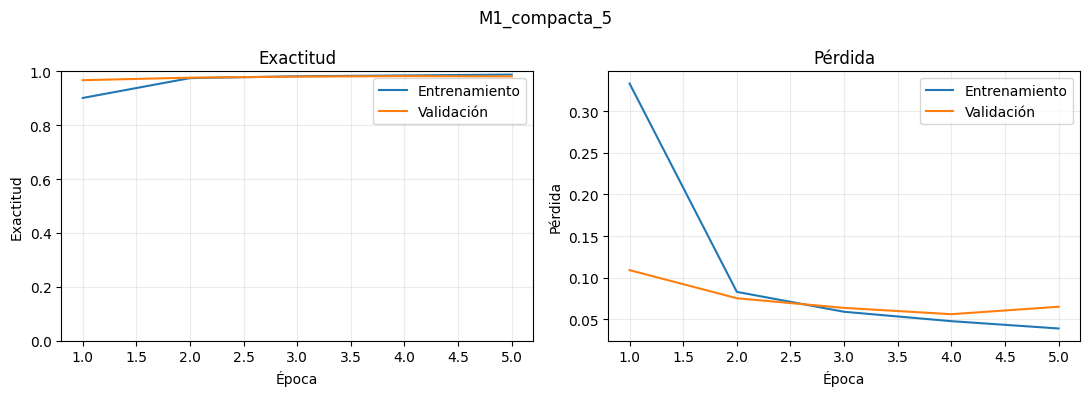


Experimento: M2_dropout_5 | Épocas: 5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100)            │       160,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 179,926 (702.84 KB)

 Trainable params: 179,926 (702.84 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
422/422 - 5s - 11ms/step - accuracy: 0.9161 - loss: 0.2739 - val_accuracy: 0.9762 - val_loss: 0.0826
Epoch 2/5
422/422 - 3s - 8ms/step - accuracy: 0.9754 - loss: 0.0807 - val_accuracy: 0.9808 - val_loss: 0.0614
Epoch 3/5
422/422 - 4s - 9ms/step - accuracy: 0.9810 - loss: 0.0617 - val_accuracy: 0.9868 - val_loss: 0.0475
Epoch 4/5
422/422 - 4s - 11ms/step - accuracy: 0.9858 - loss: 0.0472 - val_accuracy: 0.9870 - val_loss: 0.0479
Epoch 5/5
422/422 - 3s - 7ms/step - accuracy: 0.9882 - loss: 0.0388 - val_accuracy: 0.9865 - val_loss: 0.0432


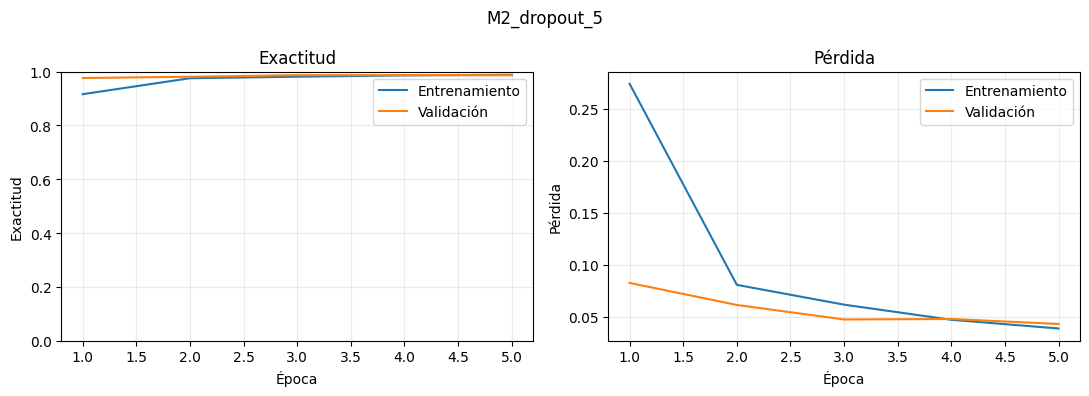


Experimento: M3_base_8 | Épocas: 8


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100)            │       160,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 179,926 (702.84 KB)

 Trainable params: 179,926 (702.84 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/8
422/422 - 5s - 11ms/step - accuracy: 0.9336 - loss: 0.2237 - val_accuracy: 0.9775 - val_loss: 0.0772
Epoch 2/8
422/422 - 3s - 7ms/step - accuracy: 0.9817 - loss: 0.0610 - val_accuracy: 0.9808 - val_loss: 0.0632
Epoch 3/8
422/422 - 3s - 7ms/step - accuracy: 0.9867 - loss: 0.0432 - val_accuracy: 0.9852 - val_loss: 0.0502
Epoch 4/8
422/422 - 6s - 13ms/step - accuracy: 0.9896 - loss: 0.0327 - val_accuracy: 0.9872 - val_loss: 0.0452
Epoch 5/8
422/422 - 3s - 7ms/step - accuracy: 0.9917 - loss: 0.0258 - val_accuracy: 0.9840 - val_loss: 0.0525
Epoch 6/8
422/422 - 3s - 7ms/step - accuracy: 0.9936 - loss: 0.0201 - val_accuracy: 0.9872 - val_loss: 0.0382
Epoch 7/8
422/422 - 6s - 14ms/step - accuracy: 0.9943 - loss: 0.0171 - val_accuracy: 0.9878 - val_loss: 0.0431
Epoch 8/8
422/422 - 3s - 7ms/step - accuracy: 0.9956 - loss: 0.0135 - val_accuracy: 0.9833 - val_loss: 0.0516


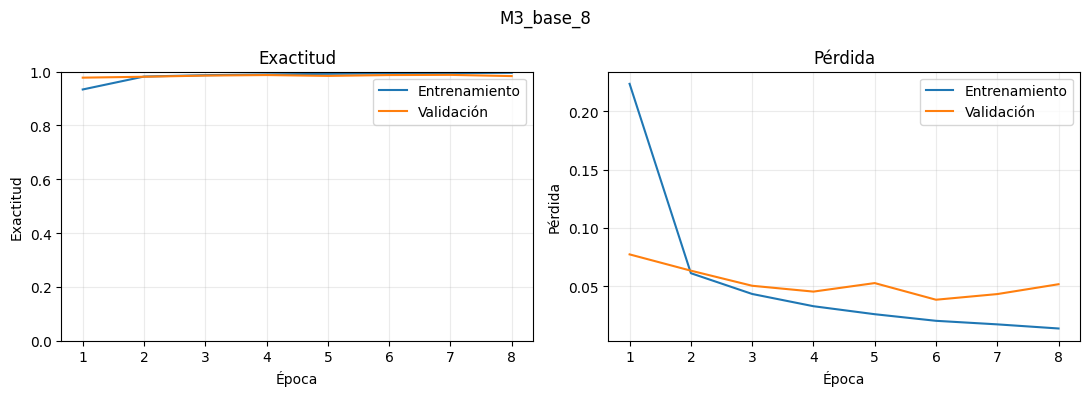

,experimento,epocas,parametros,duracion_segundos,archivo_modelo,accuracy,loss,val_accuracy,val_loss
0,M0_base_5,5,179926,23.290116,M0_base_5.keras,0.991685,0.025801,0.984000,0.052539
1,M1_compacta_5,5,56714,18.716421,M1_compacta_5.keras,0.987907,0.039135,0.981167,0.065204
2,M2_dropout_5,5,179926,19.209568,M2_dropout_5.keras,0.988185,0.038813,0.986500,0.043160
3,M3_base_8,8,179926,30.817945,M3_base_8.keras,0.995630,0.013536,0.983333,0.051558


In [5]:
def crear_mnist(filtros=(32,64), densas=100, dropout=0.0):
    capas=[layers.Input(shape=(28,28,1)),
           layers.Conv2D(filtros[0],(3,3),activation='relu'), layers.MaxPooling2D((2,2)),
           layers.Conv2D(filtros[1],(3,3),activation='relu'), layers.MaxPooling2D((2,2)),
           layers.Flatten(), layers.Dense(densas,activation='relu')]
    # Dropout solo se aplica durante entrenamiento, no durante evaluación.
    if dropout: capas.append(layers.Dropout(dropout))
    capas.append(layers.Dense(10))
    return models.Sequential(capas)

experimentos=[('M0_base_5',lambda:crear_mnist(),5),
              ('M1_compacta_5',lambda:crear_mnist((16,32),64),5),
              ('M2_dropout_5',lambda:crear_mnist(dropout=0.30),5),
              ('M3_base_8',lambda:crear_mnist(),8)]
registros=[]
for nombre,constructor,epocas in experimentos:
    registros.append(entrenar(nombre,constructor,epocas,x_train,y_train,x_val,y_val,CARPETA))
    pd.DataFrame(registros).to_csv(CARPETA/'comparacion_validacion.csv',index=False)
tabla=pd.DataFrame(registros)
tabla.to_csv(CARPETA/'comparacion_validacion.csv',index=False)
display(tabla)


## Evaluación y conclusiones a partir de resultados reales
Se elige la menor pérdida final de validación, sin mirar las etiquetas de prueba.
Se evalúan la base y la variante seleccionada sobre las mismas 10.000 imágenes de prueba.
Una pérdida de validación creciente mientras cae la de entrenamiento indica sobreajuste;
una diferencia pequeña de exactitud en una sola semilla no prueba una mejora general.


In [6]:
seleccionado=tabla.sort_values(['val_loss','parametros']).iloc[0]['experimento']
pruebas=[]
for nombre in dict.fromkeys(['M0_base_5',seleccionado]):
    resultado,_=evaluar(nombre,test_images,test_labels,CARPETA)
    pruebas.append(resultado)
test_df=pd.DataFrame(pruebas)
test_df.to_csv(CARPETA/'evaluacion_prueba.csv',index=False)
display(test_df)
base=tabla.set_index('experimento').loc['M0_base_5']
mejor=tabla.set_index('experimento').loc[seleccionado]
conclusion=(f"Se seleccionó {seleccionado} por val_loss={mejor['val_loss']:.4f}. "
            f"La base obtuvo val_loss={base['val_loss']:.4f}. "
            "El criterio de selección se fijó antes de evaluar prueba. "
            "Las curvas muestran si aumentar épocas o regularizar cambió la generalización. "
            "La conclusión se limita a esta partición y semilla.")
print(conclusion)
(CARPETA/'conclusion.txt').write_text(conclusion,encoding='utf-8')
exportar(CARPETA)


79/79 - 1s - 11ms/step - accuracy: 0.9858 - loss: 0.0440
79/79 - 1s - 7ms/step - accuracy: 0.9890 - loss: 0.0338


,experimento,test_loss,test_accuracy
0,M0_base_5,0.044019,0.9858
1,M2_dropout_5,0.033773,0.9890


Se seleccionó M2_dropout_5 por val_loss=0.0432. La base obtuvo val_loss=0.0525. El criterio de selección se fijó antes de evaluar prueba. Las curvas muestran si aumentar épocas o regularizar cambió la generalización. La conclusión se limita a esta partición y semilla.
Resultados guardados: /content/Actividad_Integradora/MNIST.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Fuente del modelo de referencia
Cátedra de Sistemas Inteligentes. *Caece - Redes neuronales convolucionales - Números - Modo Uso de RNC*.
Copia consultada en la carpeta `Archivos_Colab` del material de la asignatura.
El archivo original del profesor no se modifica.
